In [1]:
%load_ext autoreload
%autoreload 2

# 04 — Interpretabilidade

Modelo principal (HGB, `models/hgb_final.joblib`), avaliado nos municípios de teste.

1. Importância por permutação por grupo temático
2. Importância por permutação por feature
3. SHAP: contribuições e direção dos efeitos
4. Fatores dentro do estado (SHAP sem as features de território)

Ambas as técnicas medem **associação no modelo**, não efeito causal.

In [2]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

from src.evaluation.interpretabilidade import explicar_shap, grupos_interpretacao, importancia_permutacao
from src.modeling import config
from src.modeling.data import carregar_base, dividir_treino_teste

pd.set_option("display.width", 160)
IMAGES = Path("images")

modelo = joblib.load("models/hgb_final.joblib")
base = carregar_base()
features = config.selecionar_features(base.columns)
treino, teste = dividir_treino_teste(base)
print(f"Teste: {len(teste):,} municípios | {len(features)} features")


def salvar_fig(nome: str) -> None:
    plt.tight_layout()
    plt.savefig(IMAGES / f"{nome}.png", dpi=120, bbox_inches="tight")
    plt.show()

/home/user/projetos/pos-fiap/fase-3/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Teste: 1,090 municípios | 44 features


## 1. Importância por permutação — grupos temáticos

Cada grupo é embaralhado em conjunto (mesma permutação para todas as suas colunas) entre os municípios de teste; medimos a queda do % do teto. 10 repetições.

                           nome  n_features  queda_pct_teto  queda_pct_teto_dp  aumento_log_loss
       Território (UF e região)           2          0.5167             0.0398            0.0453
                  Fluxo escolar           5          0.1466             0.0307            0.0144
   Socioeconômico e demográfico          10          0.0414             0.0077            0.0044
Formação e regularidade docente          14          0.0093             0.0081            0.0005
      Financiamento da educação           5          0.0053             0.0063            0.0003
               Turmas e jornada           8          0.0023             0.0046            0.0002


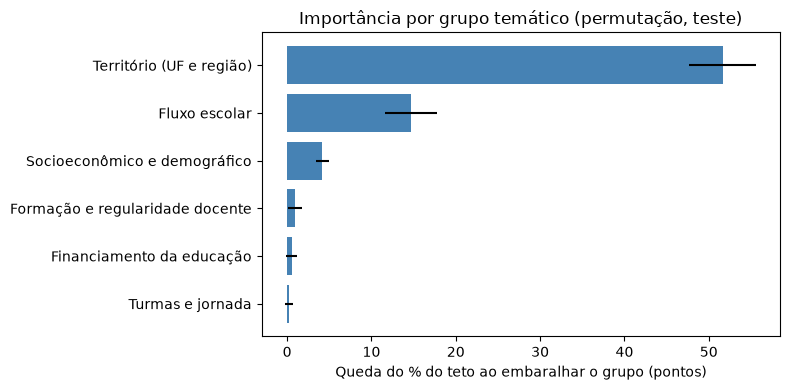

In [3]:
grupos = grupos_interpretacao(features)
importancia_grupos = importancia_permutacao(modelo, teste, features, grupos=grupos, n_repeticoes=10)
print(importancia_grupos.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4))
ordem = importancia_grupos.iloc[::-1]
ax.barh(ordem["nome"], 100 * ordem["queda_pct_teto"], xerr=100 * ordem["queda_pct_teto_dp"], color="steelblue")
ax.set_xlabel("Queda do % do teto ao embaralhar o grupo (pontos)")
ax.set_title("Importância por grupo temático (permutação, teste)")
salvar_fig("05_importancia_grupos")

## 2. Importância por permutação — features individuais

Atenção: features correlacionadas dividem o crédito quando embaralhadas uma a uma — a leitura por grupo (seção 1) é a mais robusta.

                        nome  n_features  queda_pct_teto  queda_pct_teto_dp  aumento_log_loss
                      ter_uf           1          0.5248             0.0418            0.0450
  ce_aprovacao_anos_iniciais           1          0.0298             0.0090            0.0024
   ce_abandono_anos_iniciais           1          0.0295             0.0228            0.0025
      ce_alunos_turma_creche           1          0.0148             0.0017            0.0006
           ce_distorcao_1ano           1          0.0129             0.0055            0.0003
fin_invest_aluno_fundamental           1          0.0112             0.0056            0.0008
               soc_populacao           1          0.0101             0.0078            0.0010
                  ter_regiao           1          0.0101             0.0047            0.0005
          soc_pib_per_capita           1          0.0088             0.0059            0.0005
             soc_alfab_25_44           1          0.0079    

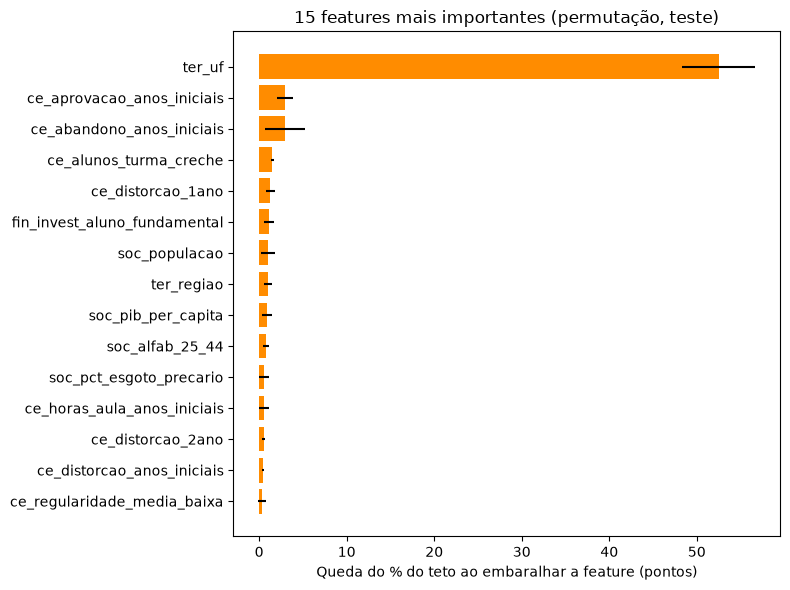

In [4]:
importancia_features = importancia_permutacao(modelo, teste, features, n_repeticoes=5)
print(importancia_features.head(15).round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 6))
top = importancia_features.head(15).iloc[::-1]
ax.barh(top["nome"], 100 * top["queda_pct_teto"], xerr=100 * top["queda_pct_teto_dp"], color="darkorange")
ax.set_xlabel("Queda do % do teto ao embaralhar a feature (pontos)")
ax.set_title("15 features mais importantes (permutação, teste)")
salvar_fig("06_importancia_features")

## 3. SHAP

PermutationExplainer sobre a matriz pré-processada (o TreeExplainer tem bug conhecido com categóricas nativas do HGB). Fundo: 50 municípios de treino; explicados: amostra aleatória de 400 municípios de teste. Valores na escala de probabilidade (contribuição para a taxa prevista). Para `ter_uf` e `ter_regiao`, a cor do gráfico reflete códigos arbitrários e não deve ser lida como "alto/baixo".

PermutationExplainer explainer: 401it [05:22,  1.20it/s]                         


Checagem aditiva — diferença máxima: 9.99e-16


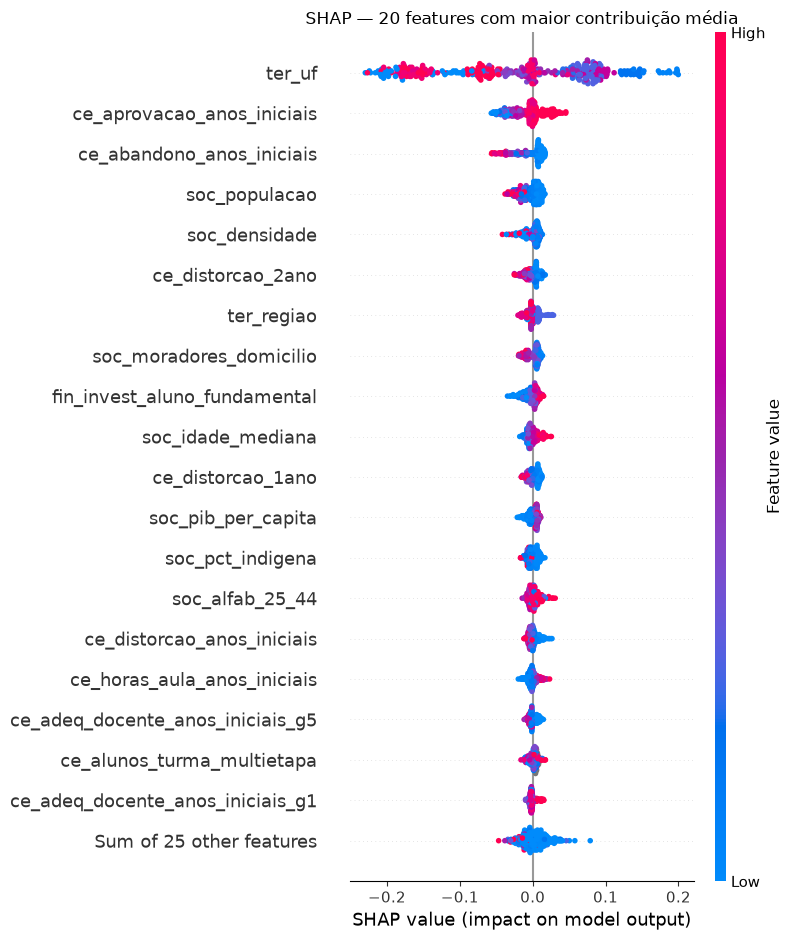

In [5]:
fundo = treino.sample(50, random_state=config.SEED)
explicados = teste.sample(400, random_state=config.SEED)

valores_shap = explicar_shap(modelo, fundo, explicados, features)

prob_explicados = modelo.predict_proba(explicados[features])[:, 1]
reconstruido = valores_shap.base_values + valores_shap.values.sum(axis=1)
print(f"Checagem aditiva — diferença máxima: {np.abs(reconstruido - prob_explicados).max():.2e}")

shap.plots.beeswarm(valores_shap, max_display=20, show=False)
plt.title("SHAP — 20 features com maior contribuição média")
salvar_fig("07_shap_beeswarm")

## 4. Fatores dentro do estado

No modelo completo, a UF absorve o efeito estadual (política educacional e instrumento de avaliação). As contribuições das demais features medem associações **entre municípios do mesmo estado**. Abaixo: contribuição média absoluta por grupo (comparável à permutação) e o beeswarm sem as features de território.

Contribuição SHAP média absoluta por grupo (pontos de probabilidade × 100):
Território (UF e região)           10.04
Socioeconômico e demográfico        5.20
Fluxo escolar                       4.88
Formação e regularidade docente     2.72
Turmas e jornada                    1.83
Financiamento da educação           1.33


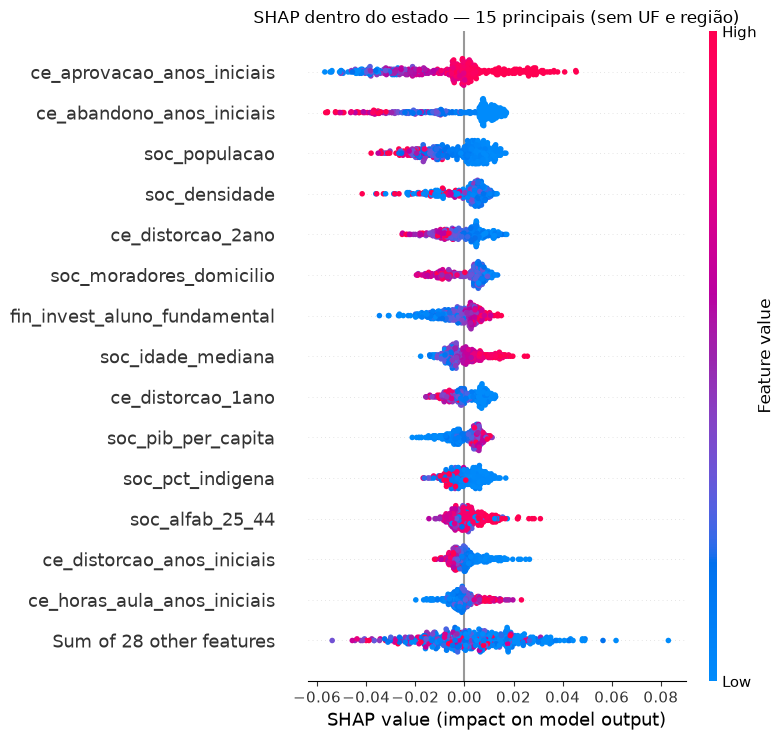

In [6]:
nomes_shap = list(valores_shap.feature_names)
contribuicao_media = pd.Series(np.abs(valores_shap.values).mean(axis=0), index=nomes_shap)

grupo_de = {feature: grupo for grupo, colunas in grupos.items() for feature in colunas}
shap_por_grupo = (
    contribuicao_media.groupby(contribuicao_media.index.map(grupo_de))
    .sum()
    .sort_values(ascending=False)
    .rename("shap_medio_absoluto")
)
print("Contribuição SHAP média absoluta por grupo (pontos de probabilidade × 100):")
print((100 * shap_por_grupo).round(2).to_string())

indices_sem_territorio = [i for i, nome in enumerate(nomes_shap) if not nome.startswith("ter_")]
shap.plots.beeswarm(valores_shap[:, indices_sem_territorio], max_display=15, show=False)
plt.title("SHAP dentro do estado — 15 principais (sem UF e região)")
salvar_fig("08_shap_dentro_do_estado")

## Conclusões

**Dependência do modelo (permutação por grupo, queda do % do teto no teste):** Território 51,7 pts; Fluxo escolar 14,7; Socioeconômico e demográfico 4,1; Formação docente 0,9, Financiamento 0,5 e Turmas/jornada 0,2 — os três últimos dentro do ruído (contribuição marginal indistinguível de zero, dado o estado e as demais features; isso não significa irrelevância causal).

**Permutação ≠ ablação:** embaralhar a UF derruba 52 pontos (o modelo depende dela), mas retreinar sem a UF custou 14 (notebook 03): outras features reconstroem parte do efeito estadual.

**Direções dentro do estado (SHAP sem UF e região):**
- Fluxo: aprovação maior → taxa maior; abandono e distorção idade-série maiores → taxa menor.
- Porte: população e densidade maiores → taxa menor (municípios grandes e urbanos alfabetizam menos dentro do mesmo estado).
- Vulnerabilidade: mais moradores por domicílio e PIB per capita baixo → taxa menor.
- Educação: maior investimento por aluno no fundamental, maior alfabetização da geração dos pais e mais horas-aula nos anos iniciais → taxa maior.
- % de população indígena maior → taxa menor (contexto de política educacional — ex.: alfabetização em português como segunda língua —, não causa).

**Escala:** cada fator local desloca a previsão em ~2–5 p.p.; o efeito estadual chega a ±20 p.p. O estado em que o município está é o fator mais associado — e ele mistura política educacional estadual e diferenças de instrumento de avaliação.

Todas as leituras são **associações no modelo**, não efeitos causais.